# Tutorial 1 — Reading and visualising common rheological datasets

This tutorial shows how to load rheometer exports with `hermes_rheo` and plot them:

1. A [TA Instruments](https://www.tainstruments.com/) TRIOS `.txt` export containing a single creep test.
2. A TRIOS `.txt` export containing several test types (amplitude sweep, frequency sweep, flow ramp).
3. An [Anton Paar](https://www.anton-paar.com/us-en/) RheoCompass `.csv` export of a time-temperature superposition (tTS) frequency-sweep series.

:::{seealso}
- [`hermes_rheo.file_readers`](https://3mcloud.github.io/hermes-rheo/file_readers.html): reader API reference.
- Tutorial 3 covers OWChirp experiments, which need the dedicated [`OWChirpAnalysis`](https://3mcloud.github.io/hermes-rheo/transforms.html#module-hermes_rheo.transforms.owchirp_analysis) transform.
:::

:::{important}
**Exporting TRIOS files.** `TriosRheoReader` needs the step-header metadata (geometry, calibration, wave parameters) that only two export paths include:

- **TRIOS 5 and earlier:** *Send to LIMS*.
- **TRIOS 6.0 and later:** *Export* → *Export to .txt (Full)*. The plain *Export to .txt* option omits this metadata and cannot be parsed.

TRIOS is a free download from [TA Instruments](https://www.tainstruments.com/support/software-downloads-support/downloads/).
:::

## Supported instruments

| Instrument / software | File type | Reader class |
|---|---|---|
| [TA Instruments](https://www.tainstruments.com/) TRIOS | `.txt` (*Send to LIMS* or *Export to .txt (Full)*) | `TriosRheoReader` |
| [Anton Paar](https://www.anton-paar.com/us-en/) RheoCompass | `.csv` | `RheoCompassReader` |

All readers are used the same way: `read_file` takes the file path and, optionally, the reader class. If no reader is given, it is chosen from the file extension (`.txt` → TRIOS, `.csv` → RheoCompass).

### Imports

In [1]:
import os

import matplotlib.pyplot as plt

from hermes_rheo import read_file
from hermes_rheo.file_readers.rheo_compass_csv import RheoCompassReader
from hermes_rheo.file_readers.trios_rheo_txt import TriosRheoReader

# Publication-style Matplotlib settings (LaTeX rendering is disabled so this works everywhere).
from hermes_rheo.visualization import use_science_style

use_science_style()

['science', 'notebook', 'no-latex']

### Data files

In [2]:
# Folder containing this notebook; the data live in tutorial_data/tutorial_1/.
notebook_dir = os.path.dirname(os.path.abspath("__file__"))
data_dir = os.path.join(notebook_dir, "tutorial_data", "tutorial_1")

filepath_creep = os.path.join(data_dir, "creep_experiment.txt")  # TRIOS, creep test
filepath_multi_technique = os.path.join(data_dir, "multi_technique.txt")  # TRIOS, 3 test types
filepath_anton_paar_tts = os.path.join(data_dir, "anton_paar_tts.csv")  # RheoCompass, tTS series

## 1. TRIOS file with a single test

`read_file` returns an `ExperimentSet` when all measurements in the file are of the same kind. For a creep step, each dataset holds `strain` as a function of `time`, so it can be plotted directly.

In [3]:
creep_experiments = read_file(
    filepath_creep,
    file_reader=TriosRheoReader,
    create_composite_datasets=True,
)
print(creep_experiments)

ExperimentSet
-------------

Summary
-------
Number of Experiments: 1

Varied Conditions
----------------

index	n_rep	method	Data Types	
0	1	Creep - 1	strain(%)=f(time[min]) (483 points)	




ExperimentSet
-------------

Summary
-------
Number of Experiments: 1

Varied Conditions
----------------

index	n_rep	method	Data Types	
0	1	Creep - 1	strain(%)=f(time[min]) (483 points)	




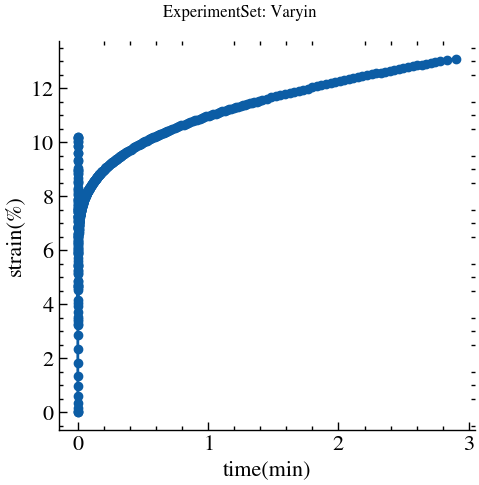

In [4]:
fig_creep, axes_creep = creep_experiments.visualize(expand_replicates=True, marker="o")

## 2. TRIOS file with several test types

A single TRIOS file can hold different tests in sequence, here an amplitude sweep, a frequency sweep and a flow ramp. They have different axes, so they cannot be grouped in one `ExperimentSet`. Passing `to_experiments=False` returns a `MeasurementSet` instead, where each measurement keeps the axes that suit its test type:

- amplitude sweep: $G'$ vs. oscillation strain
- frequency sweep: $G'$ vs. angular frequency
- flow ramp: viscosity vs. shear rate

:::{tip}
To force the same placeholder axes on every measurement and keep the `ExperimentSet` structure, read with `default_coords="uniform"` and select the axes later with `switch_coordinates()`.
:::

In [5]:
multi_technique_measurements = read_file(
    filepath_multi_technique,
    file_reader=TriosRheoReader,
    create_composite_datasets=True,
    to_experiments=False,
)

# One line per measurement: test type and the axes it is plotted on.
for measurement in multi_technique_measurements.measurements:
    dataset = measurement.datasets[0]
    print(
        f"{measurement.conditions['method']:<22}"
        f"{dataset.dependent_variable_name} vs. {dataset.independent_variable_name}"
    )

Amplitude sweep - 1   storage modulus vs. oscillation strain (cmd)
Frequency sweep - 2   storage modulus vs. angular frequency
Flow ramp - 3         viscosity vs. shear rate


### Selecting a measurement

Measurements are indexed in the order they appear in the file. Each holds a list of datasets, and `visualize()` plots the dataset on its default axes.

In [6]:
amplitude_sweep = multi_technique_measurements[0].datasets[0]
frequency_sweep = multi_technique_measurements[1].datasets[0]
flow_ramp = multi_technique_measurements[2].datasets[0]

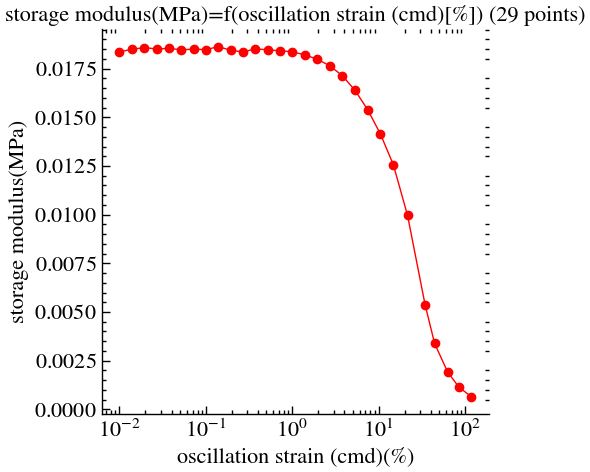

In [7]:
# Amplitude sweep
fig_amplitude, ax_amplitude = amplitude_sweep.visualize(marker="o", linewidth=1, color="red")
fig_amplitude.set_size_inches(5, 5)
ax_amplitude.set_xscale("log")

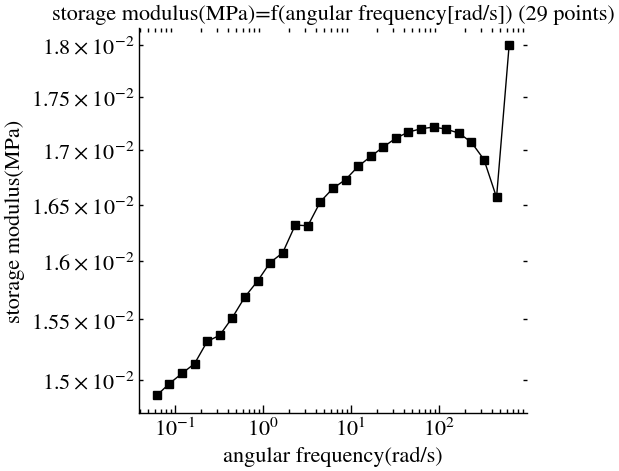

In [8]:
# Frequency sweep
fig_frequency, ax_frequency = frequency_sweep.visualize(
    marker="s", linewidth=1, color="black"
)
fig_frequency.set_size_inches(5, 5)
ax_frequency.set_xscale("log")
ax_frequency.set_yscale("log")

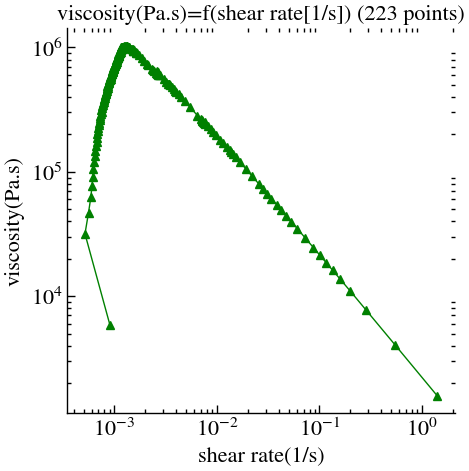

In [9]:
# Flow ramp
fig_flow, ax_flow = flow_ramp.visualize(marker="^", linewidth=1, color="green")
fig_flow.set_size_inches(5, 5)
ax_flow.set_xscale("log")
ax_flow.set_yscale("log")

### Accessing the numerical data

The arrays behind a plot are available as `x_values` (independent variable) and `y_values` (dependent variable).

In [10]:
oscillation_strain = amplitude_sweep.x_values
storage_modulus = amplitude_sweep.y_values

print(f"{amplitude_sweep.independent_variable_name}: {oscillation_strain[:5]} ...")
print(f"{amplitude_sweep.dependent_variable_name}: {storage_modulus[:5]} ...")

oscillation strain (cmd): [+0.0099 +0.0139 ... +0.0269 +0.0373] ...
storage modulus: [+0.0184 +0.0185 ... +0.0185 +0.0185] ...


## 3. Anton Paar RheoCompass file

`RheoCompassReader` reads the `.csv` export of RheoCompass and is used exactly like the TRIOS reader. The file below is a time-temperature superposition (tTS) series: isothermal frequency sweeps measured at different temperatures. Each interval in the file becomes one measurement.

In [11]:
anton_paar_experiments = read_file(
    filepath_anton_paar_tts,
    file_reader=RheoCompassReader,
    create_composite_datasets=True,
)
print(anton_paar_experiments)

ExperimentSet
-------------

Summary
-------
Number of Experiments: 33

Varied Conditions
-----------------
method

index	n_rep	method	Data Types	
0	1	Interval 1 (Fs - 100.11)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
1	1	Interval 1 (Fs - 94.98)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
2	1	Interval 1 (Fs - 89.98)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
3	1	Interval 1 (Fs - 84.97)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
4	1	Interval 1 (Fs - 79.98)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
5	1	Interval 1 (Fs - 74.98)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
6	1	Interval 1 (Fs - 69.97)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
7	1	Interval 1 (Fs - 64.97)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
8	1	Interval 1 (Fs - 59.95)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
9	1	In

Text(0.5, 1.0, 'Anton Paar RheoCompass: first frequency sweep')

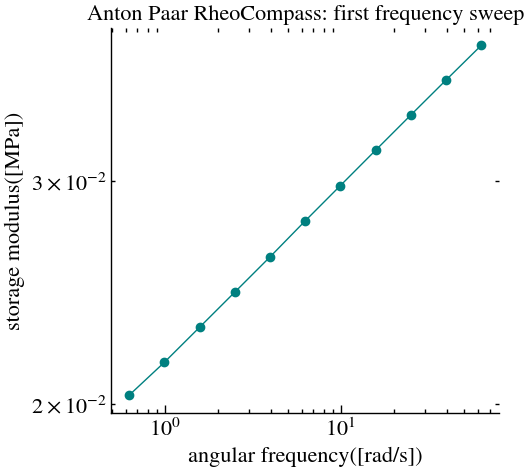

In [12]:
first_frequency_sweep = anton_paar_experiments[0][0].datasets[0]

fig_ap, ax_ap = first_frequency_sweep.visualize(marker="o", linewidth=1, color="teal")
fig_ap.set_size_inches(5, 5)
ax_ap.set_xscale("log")
ax_ap.set_yscale("log")
ax_ap.set_title("Anton Paar RheoCompass: first frequency sweep")